In [5]:
from google.colab import files
import pandas as pd
import io

uploaded = files.upload()

filename = next(iter(uploaded))
workbook = pd.ExcelFile(io.BytesIO(uploaded[filename]))

print("Uploaded:", filename)
print("Worksheets:", workbook.sheet_names)

Saving Raw_WDI_Data_Africa.xlsx to Raw_WDI_Data_Africa (2).xlsx
Uploaded: Raw_WDI_Data_Africa (2).xlsx
Worksheets: ['Data (2)', 'Data', 'Series - Metadata', 'WDI_Long']


In [6]:
raw_df = pd.read_excel(workbook, sheet_name="Data (2)")

print("Rows and columns:", raw_df.shape)
display(raw_df.head())

Rows and columns: (694, 18)


,Country Name,Country Code,Series Name,Series Code,2010 [YR2010],2011 [YR2011],2012 [YR2012],2013 [YR2013],2014 [YR2014],2015 [YR2015],2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023]
0,Angola,AGO,Current health expenditure (% of GDP),SH.XPD.CHEX.GD.ZS,2.363739,2.355619,2.136773,2.429772,2.1568,2.299669,2.390687,2.437943,2.298875,2.203943,2.816889,2.739871,2.60041,2.546929
1,Angola,AGO,Current health expenditure per capita (current...,SH.XPD.CHEX.PC.CD,96.951973,122.118881,121.84848,142.7845,130.586197,107.528572,94.014816,112.753647,83.875557,64.446609,56.016418,66.94487,103.945061,76.071182
2,Angola,AGO,Domestic general government health expenditure...,SH.XPD.GHED.GD.ZS,1.468266,1.52543,1.394342,1.507183,1.167978,1.089243,1.055208,1.128247,0.979819,1.00304,1.460554,1.516765,1.307118,1.13403
3,Angola,AGO,Domestic general government health expenditure...,SH.XPD.GHED.GE.ZS,4.249568,4.580569,4.201513,4.575401,3.61568,4.562625,5.432697,5.364319,5.364319,5.506884,7.305022,8.777366,6.699635,5.895757
4,Angola,AGO,Out-of-pocket expenditure (% of current health...,SH.XPD.OOPC.CH.ZS,19.343756,17.993809,17.619177,21.349277,26.876167,33.523167,35.208931,34.121014,36.247334,33.143085,28.622181,26.117256,30.038616,32.546677


In [7]:
# Keep rows with both a country code and an indicator code.
source_df = raw_df.dropna(
    subset=["Country Code", "Series Code"]
).copy()

duplicate_count = source_df.duplicated(
    subset=["Country Code", "Series Code"]
).sum()

print("Source rows:", len(source_df))
print("Countries:", source_df["Country Code"].nunique())
print("Indicators:", source_df["Series Code"].nunique())
print("Duplicate country–indicator records:", duplicate_count)

Source rows: 689
Countries: 53
Indicators: 13
Duplicate country–indicator records: 0


In [8]:
year_columns = [f"{year} [YR{year}]" for year in range(2010, 2024)]

long_df = source_df.melt(
    id_vars=["Country Name", "Country Code", "Series Name", "Series Code"],
    value_vars=year_columns,
    var_name="Year",
    value_name="Value"
)

long_df["Year"] = long_df["Year"].str[:4].astype(int)
long_df["Value"] = pd.to_numeric(long_df["Value"], errors="coerce")

print("Country–indicator–year rows:", len(long_df))

missing_summary = (
    long_df.groupby("Series Name")["Value"]
    .agg(total="size", available="count")
)
missing_summary["missing"] = (
    missing_summary["total"] - missing_summary["available"]
)

display(missing_summary)

Country–indicator–year rows: 9646


,total,available,missing
Series Name,,,
Current health expenditure (% of GDP),742,732,10
Current health expenditure per capita (current US$),742,732,10
Domestic general government health expenditure (% of GDP),742,732,10
Domestic general government health expenditure (% of general government expenditure),742,732,10
GDP per capita (current US$),742,722,20
"GDP per capita, PPP (current international $)",742,722,20
"Life expectancy at birth, total (years)",742,742,0
"Maternal mortality ratio (national estimate, per 100,000 live births)",742,47,695
"Mortality rate, under-5 (per 1,000 live births)",742,742,0


In [9]:
panel_df = long_df.pivot(
    index=["Country Code", "Year"],
    columns="Series Code",
    values="Value"
).reset_index()

country_names = source_df[
    ["Country Code", "Country Name"]
].drop_duplicates()

panel_df = panel_df.merge(
    country_names,
    on="Country Code",
    how="left",
    validate="many_to_one"
)

panel_df.columns.name = None

print("Country–year rows:", len(panel_df))
print("Countries:", panel_df["Country Code"].nunique())
print("Years:", panel_df["Year"].nunique())
print(
    "Duplicate country–year rows:",
    panel_df.duplicated(["Country Code", "Year"]).sum()
)

Country–year rows: 742
Countries: 53
Years: 14
Duplicate country–year rows: 0


In [10]:
caf_mortality = panel_df.loc[
    panel_df["Country Code"].eq("CAF"),
    ["Year", "SH.DYN.MORT"]
].rename(columns={
    "SH.DYN.MORT": "Under-five deaths per 1,000 live births"
})

display(caf_mortality.sort_values("Year"))

,Year,"Under-five deaths per 1,000 live births"
70,2010,150.7
71,2011,125.1
72,2012,121.9
73,2013,134.2
74,2014,186.8
75,2015,113.7
76,2016,126.8
77,2017,155.2
78,2018,120.2
79,2019,254.7


In [12]:
analysis_df = panel_df.rename(columns={
    "SH_UHC_SCI": "uhc_service_coverage",
    "SP.DYN.LE00.IN": "life_expectancy",
    "SH.DYN.MORT": "under5_mortality",
    "NY.GDP.PCAP.CD": "gdp_per_capita",
    "SH.XPD.CHEX.PC.CD": "health_expenditure_per_capita",
    "SH.XPD.GHED.GD.ZS": "government_health_expenditure_gdp",
    "SH.XPD.OOPC.CH.ZS": "out_of_pocket_expenditure"
}).copy()

main_variables = [
    "uhc_service_coverage",
    "life_expectancy",
    "under5_mortality",
    "gdp_per_capita",
    "health_expenditure_per_capita",
    "government_health_expenditure_gdp",
    "out_of_pocket_expenditure"
]

print(analysis_df[main_variables].describe().T.to_string())

                                   count         mean          std         min         25%          50%          75%           max
uhc_service_coverage               742.0    48.134771    13.572444   21.000000   39.000000    46.000000    56.000000     81.000000
life_expectancy                    742.0    62.500653     6.871865   18.818000   58.860000    62.294500    66.116000     77.236585
under5_mortality                   742.0    67.233558    40.988847   10.400000   42.625000    59.650000    90.000000    424.600000
gdp_per_capita                     722.0  2705.372764  3243.813169  216.727705  758.687369  1358.882528  3492.915839  19141.511874
health_expenditure_per_capita      732.0   132.407123   157.445487   11.766190   35.759585    63.561354   162.374302    766.287781
government_health_expenditure_gdp  732.0     1.798735     1.342338    0.099050    0.818926     1.350601     2.309926      6.754378
out_of_pocket_expenditure          732.0    37.290929    19.449577    2.993242   23

In [13]:
print("Ten lowest life-expectancy observations:")

print(
    analysis_df.nsmallest(10, "life_expectancy")[
        [
            "Country Name",
            "Year",
            "life_expectancy",
            "under5_mortality"
        ]
    ].to_string(index=False)
)

Ten lowest life-expectancy observations:
            Country Name  Year  life_expectancy  under5_mortality
Central African Republic  2022           18.818             424.6
Central African Republic  2019           31.530             254.7
      Somalia, Fed. Rep.  2011           32.453             363.1
             South Sudan  2017           35.351             292.0
             South Sudan  2016           36.720             272.9
             South Sudan  2015           39.757             240.8
Central African Republic  2014           40.265             186.8
Central African Republic  2021           40.279             178.7
Central African Republic  2017           45.231             155.2
             South Sudan  2014           45.625             182.6


In [14]:
metadata_df = pd.read_excel(
    workbook,
    sheet_name="Series - Metadata"
)

selected_metadata = metadata_df.loc[
    metadata_df["Code"].isin(["SP.DYN.LE00.IN", "SH.DYN.MORT"]),
    ["Code", "Indicator Name", "Source", "Reference period",
     "Limitations and exceptions", "General comments"]
]

print(selected_metadata.to_string(index=False))

          Code                                  Indicator Name                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                         Source Reference period                                                                                                                                                                                                                                                                                                                                                                          

In [15]:
from google.colab import files

checkpoint = "africa_health_financing_checkpoint.csv"
analysis_df.to_csv(checkpoint, index=False)

files.download(checkpoint)

print("Checkpoint saved and download requested.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Checkpoint saved and download requested.


In [16]:
import numpy as np

# Log only positive values; leave missing/nonpositive values missing.
for variable in ["gdp_per_capita", "health_expenditure_per_capita"]:
    analysis_df[f"log_{variable}"] = np.log(
        analysis_df[variable].where(analysis_df[variable] > 0)
    )

regression_variables = [
    "uhc_service_coverage",
    "life_expectancy",
    "under5_mortality",
    "log_gdp_per_capita",
    "log_health_expenditure_per_capita",
    "government_health_expenditure_gdp",
    "out_of_pocket_expenditure"
]

regression_df = analysis_df.dropna(
    subset=regression_variables
).copy()

print("Regression observations:", len(regression_df))
print("Countries:", regression_df["Country Code"].nunique())
print("Years:", regression_df["Year"].nunique())

print("\nExcluded country–year rows:")
excluded = analysis_df.loc[
    ~analysis_df.index.isin(regression_df.index)
]
print(excluded.groupby("Country Name").size().to_string())

Regression observations: 713
Countries: 52
Years: 14

Excluded country–year rows:
Country Name
Eritrea               12
Somalia, Fed. Rep.     3
South Sudan           14


In [17]:
import statsmodels.formula.api as smf

uhc_model = smf.ols(
    "uhc_service_coverage ~ "
    "log_gdp_per_capita + log_health_expenditure_per_capita "
    "+ C(Q('Country Code')) + C(Year)",
    data=regression_df
).fit(
    cov_type="cluster",
    cov_kwds={"groups": regression_df["Country Code"]},
    use_t=True
)

terms = [
    "log_gdp_per_capita",
    "log_health_expenditure_per_capita"
]

uhc_results = pd.DataFrame({
    "Coefficient": uhc_model.params,
    "Standard error": uhc_model.bse,
    "P-value": uhc_model.pvalues,
    "95% CI lower": uhc_model.conf_int()[0],
    "95% CI upper": uhc_model.conf_int()[1]
}).loc[terms]

print(uhc_results.round(4).to_string())

                                   Coefficient  Standard error  P-value  95% CI lower  95% CI upper
log_gdp_per_capita                      2.3407          1.7468   0.1862       -1.1661        5.8476
log_health_expenditure_per_capita      -0.3845          0.9428   0.6851       -2.2773        1.5083


In [18]:
outcomes = [
    "uhc_service_coverage",
    "life_expectancy",
    "under5_mortality"
]

financing_variables = [
    "log_health_expenditure_per_capita",
    "government_health_expenditure_gdp",
    "out_of_pocket_expenditure"
]

fitted_models = {}
results = []

for outcome in outcomes:
    for financing in financing_variables:
        model = smf.ols(
            f"{outcome} ~ log_gdp_per_capita + {financing} "
            "+ C(Q('Country Code')) + C(Year)",
            data=regression_df
        ).fit(
            cov_type="cluster",
            cov_kwds={"groups": regression_df["Country Code"]},
            use_t=True
        )

        fitted_models[(outcome, financing)] = model
        ci = model.conf_int().loc[financing]

        results.append({
            "Outcome": outcome,
            "Financing indicator": financing,
            "Coefficient": model.params[financing],
            "P-value": model.pvalues[financing],
            "95% CI lower": ci.iloc[0],
            "95% CI upper": ci.iloc[1],
            "Observations": int(model.nobs)
        })

model_results = pd.DataFrame(results)
print(model_results.round(4).to_string(index=False))

             Outcome               Financing indicator  Coefficient  P-value  95% CI lower  95% CI upper  Observations
uhc_service_coverage log_health_expenditure_per_capita      -0.3845   0.6851       -2.2773        1.5083           713
uhc_service_coverage government_health_expenditure_gdp      -0.0205   0.9592       -0.8211        0.7801           713
uhc_service_coverage         out_of_pocket_expenditure       0.0036   0.9204       -0.0686        0.0758           713
     life_expectancy log_health_expenditure_per_capita      -1.6405   0.1135       -3.6856        0.4046           713
     life_expectancy government_health_expenditure_gdp      -0.2940   0.3798       -0.9602        0.3722           713
     life_expectancy         out_of_pocket_expenditure      -0.0071   0.6310       -0.0364        0.0223           713
    under5_mortality log_health_expenditure_per_capita       7.3335   0.3664       -8.8229       23.4898           713
    under5_mortality government_health_expenditu

In [20]:
model_results.to_csv("fixed_effects_results.csv", index=False)
regression_df.to_csv("regression_sample.csv", index=False)

import zipfile

with zipfile.ZipFile("capstone_results_checkpoint.zip", "w") as archive:
    archive.write("fixed_effects_results.csv")
    archive.write("regression_sample.csv")

files.download("capstone_results_checkpoint.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
flagged_records = [
    ("CAF", 2014),
    ("CAF", 2019),
    ("CAF", 2021),
    ("CAF", 2022),
    ("SLE", 2010)
]

flagged = regression_df.set_index(
    ["Country Code", "Year"]
).index.isin(flagged_records)

sensitivity_df = regression_df.loc[~flagged].copy()

sensitivity_model = smf.ols(
    "under5_mortality ~ log_gdp_per_capita "
    "+ log_health_expenditure_per_capita "
    "+ C(Q('Country Code')) + C(Year)",
    data=sensitivity_df
).fit(
    cov_type="cluster",
    cov_kwds={"groups": sensitivity_df["Country Code"]},
    use_t=True
)

comparison_rows = []

for label, model in [
    (
        "Full sample",
        fitted_models[
            ("under5_mortality", "log_health_expenditure_per_capita")
        ]
    ),
    ("Historical five-record exclusion", sensitivity_model)
]:
    term = "log_health_expenditure_per_capita"
    ci = model.conf_int().loc[term]

    comparison_rows.append({
        "Sample": label,
        "Observations": int(model.nobs),
        "Spending coefficient": model.params[term],
        "P-value": model.pvalues[term],
        "95% CI lower": ci.iloc[0],
        "95% CI upper": ci.iloc[1]
    })

sensitivity_results = pd.DataFrame(comparison_rows)
print(sensitivity_results.round(4).to_string(index=False))

                          Sample  Observations  Spending coefficient  P-value  95% CI lower  95% CI upper
                     Full sample           713                7.3335   0.3664       -8.8229       23.4898
Historical five-record exclusion           708               -0.4913   0.8609       -6.0932        5.1107


In [22]:
log_mortality_df = regression_df.loc[
    regression_df["under5_mortality"] > 0
].copy()

log_mortality_df["log_under5_mortality"] = np.log(
    log_mortality_df["under5_mortality"]
)

log_mortality_model = smf.ols(
    "log_under5_mortality ~ log_gdp_per_capita "
    "+ log_health_expenditure_per_capita "
    "+ C(Q('Country Code')) + C(Year)",
    data=log_mortality_df
).fit(
    cov_type="cluster",
    cov_kwds={"groups": log_mortality_df["Country Code"]},
    use_t=True
)

term = "log_health_expenditure_per_capita"
ci = log_mortality_model.conf_int().loc[term]

log_mortality_results = pd.DataFrame([{
    "Observations": int(log_mortality_model.nobs),
    "Spending coefficient": log_mortality_model.params[term],
    "P-value": log_mortality_model.pvalues[term],
    "95% CI lower": ci.iloc[0],
    "95% CI upper": ci.iloc[1]
}])

print(log_mortality_results.round(4).to_string(index=False))

 Observations  Spending coefficient  P-value  95% CI lower  95% CI upper
          713                0.0305   0.6189       -0.0918        0.1528


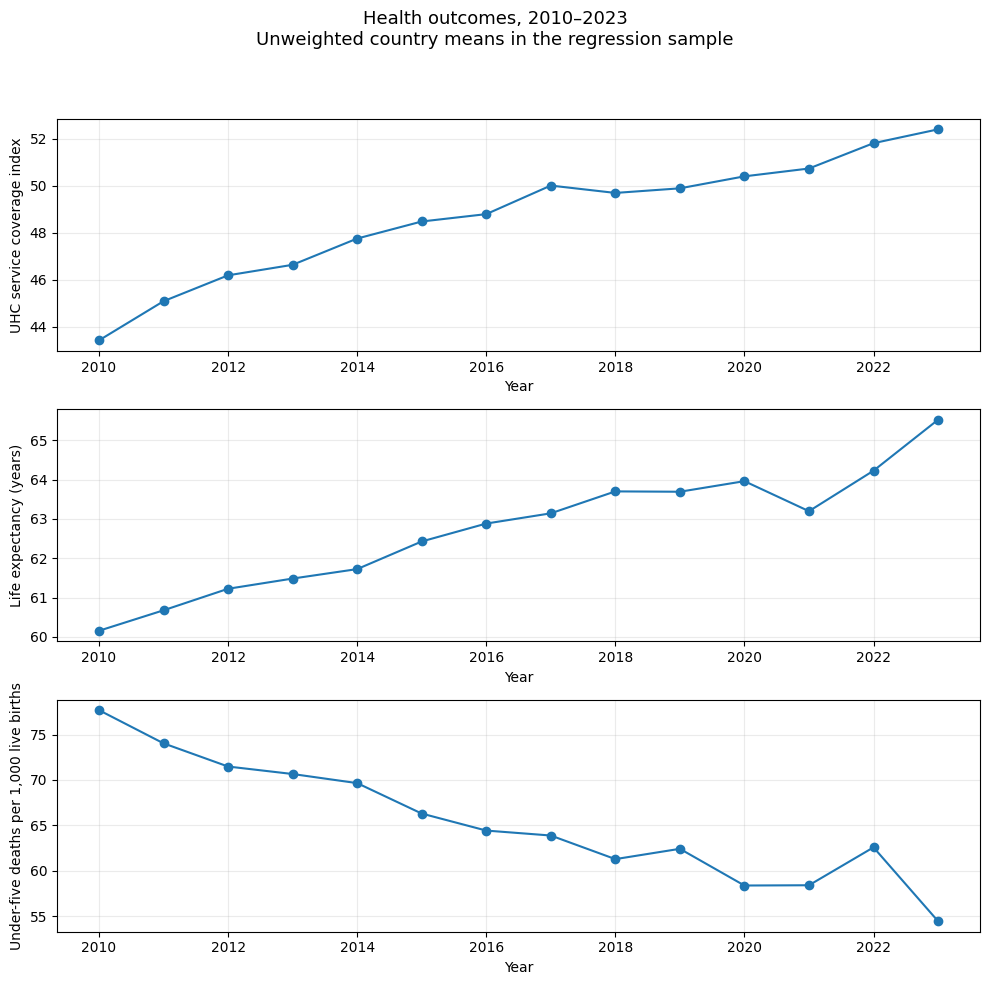

Countries included each year:
Year
2010    51
2011    51
2012    50
2013    51
2014    51
2015    51
2016    51
2017    51
2018    51
2019    51
2020    51
2021    51
2022    51
2023    51


In [23]:
import matplotlib.pyplot as plt

outcome_labels = {
    "uhc_service_coverage": "UHC service coverage index",
    "life_expectancy": "Life expectancy (years)",
    "under5_mortality": "Under-five deaths per 1,000 live births"
}

annual_means = regression_df.groupby("Year")[
    list(outcome_labels)
].mean()

annual_counts = regression_df.groupby("Year").size()

fig, axes = plt.subplots(3, 1, figsize=(10, 10))

for ax, (variable, label) in zip(axes, outcome_labels.items()):
    ax.plot(annual_means.index, annual_means[variable], marker="o")
    ax.set_ylabel(label)
    ax.set_xlabel("Year")
    ax.grid(alpha=0.25)

fig.suptitle(
    "Health outcomes, 2010–2023\n"
    "Unweighted country means in the regression sample",
    fontsize=13
)

fig.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig("health_outcome_trends.png", dpi=200, bbox_inches="tight")
plt.show()

print("Countries included each year:")
print(annual_counts.to_string())

These figures show unweighted annual country means for the complete-case regression sample: 51 countries per year, except 2012 (50). Country membership varies across years. Overall, UHC coverage and life expectancy increased while under-five mortality declined. Unusual source observations remain under verification, so individual annual fluctuations should be interpreted cautiously. These descriptive trends do not establish that health financing caused the changes.

In [24]:
files.download("health_outcome_trends.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

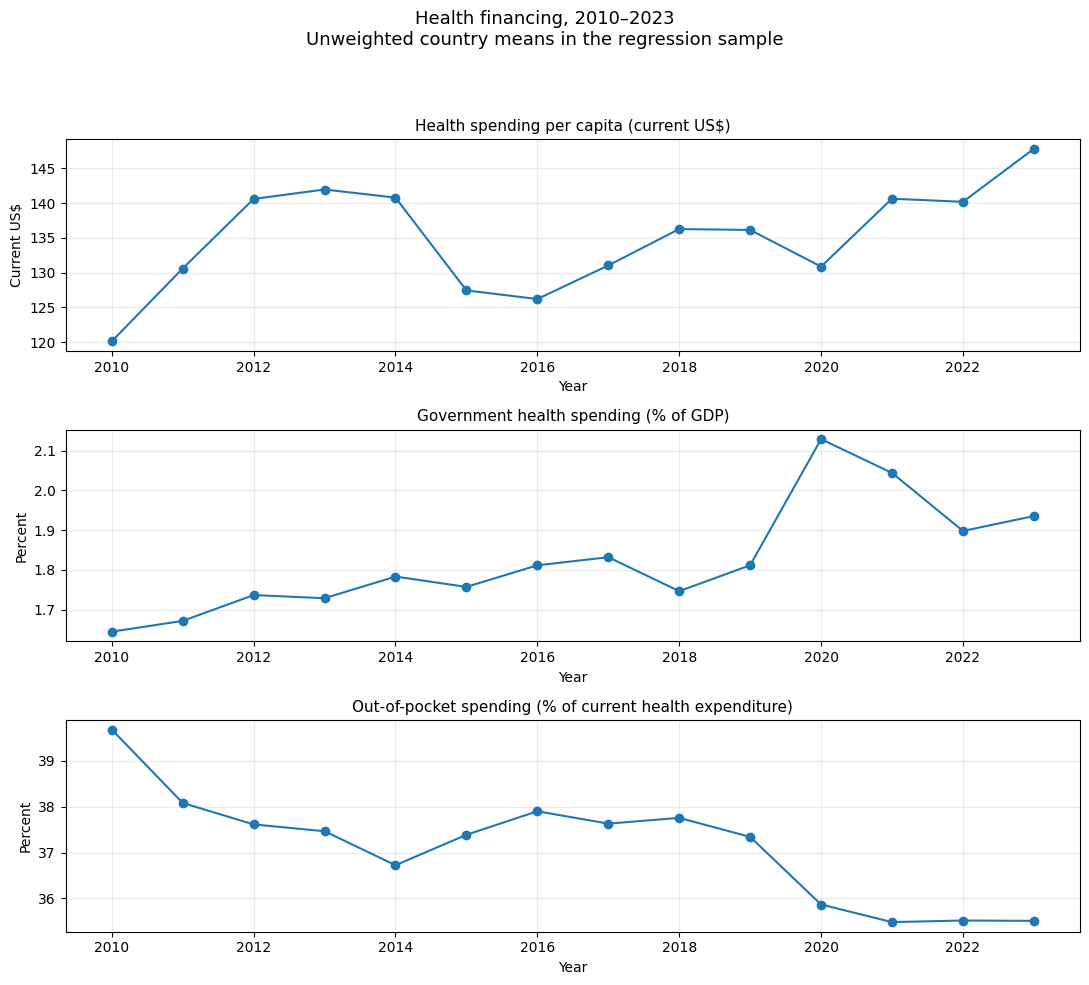

In [25]:
financing_labels = {
    "health_expenditure_per_capita":
        "Health spending per capita (current US$)",
    "government_health_expenditure_gdp":
        "Government health spending (% of GDP)",
    "out_of_pocket_expenditure":
        "Out-of-pocket spending (% of current health expenditure)"
}

annual_financing = regression_df.groupby("Year")[
    list(financing_labels)
].mean()

fig, axes = plt.subplots(3, 1, figsize=(11, 10))

for ax, (variable, label) in zip(axes, financing_labels.items()):
    ax.plot(
        annual_financing.index,
        annual_financing[variable],
        marker="o"
    )
    ax.set_title(label, fontsize=11)
    ax.set_xlabel("Year")
    ax.set_ylabel("Current US$" if variable == "health_expenditure_per_capita"
                  else "Percent")
    ax.grid(alpha=0.25)

fig.suptitle(
    "Health financing, 2010–2023\n"
    "Unweighted country means in the regression sample",
    fontsize=13
)

fig.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig("health_financing_trends.png", dpi=200, bbox_inches="tight")
plt.show()

These figures show unweighted annual country means for the regression sample: 51 countries per year, except 2012 (50). Health spending per capita fluctuated but ended above its 2010 level. Government health spending as a share of GDP peaked in 2020, while the out-of-pocket share ended below its 2010 level.

Per-capita spending is measured in current US dollars and is not adjusted for inflation or exchange-rate changes. A falling out-of-pocket share does not necessarily mean households paid less in absolute terms or experienced less financial hardship. Country membership varies across years, and these descriptive trends do not establish causal relationships.

In [26]:
files.download("health_financing_trends.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
from pathlib import Path
import zipfile

export_folder = Path("capstone_outputs")
export_folder.mkdir(exist_ok=True)

tables = {
    "main_regression_results.csv": model_results,
    "mortality_exclusion_sensitivity.csv": sensitivity_results,
    "log_mortality_sensitivity.csv": log_mortality_results,
    "annual_health_outcome_means.csv": annual_means,
    "annual_financing_means.csv": annual_financing,
    "annual_country_counts.csv": annual_counts.rename("countries").to_frame()
}

for filename, table in tables.items():
    table.to_csv(
        export_folder / filename,
        index=filename.startswith("annual_")
    )

regression_df.to_csv(
    export_folder / "regression_sample.csv", index=False
)

with zipfile.ZipFile("capstone_outputs.zip", "w") as archive:
    for path in export_folder.glob("*.csv"):
        archive.write(path, arcname=path.name)

    for filename in [
        "health_outcome_trends.png",
        "health_financing_trends.png"
    ]:
        archive.write(filename, arcname=filename)

files.download("capstone_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>